# RQ3 Analysis: Lexical Density

Compares lexical density of human-written PR descriptions and AI-generated descriptions across six context variations.

- Models: `meta-llama/llama-3.1-70b-instruct`, `gpt-5-mini-2025-08-07`, `Qwen/Qwen2.5-72B-Instruct`
- Formula: `Lexical Density = content_words / total_tokens`
- Content POS tags: `NOUN`, `PROPN`, `VERB`, `ADJ`, `ADV`
- POS tagging: spaCy `en_core_web_sm`

In [1]:
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt_tab', quiet=True)


True

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from pathlib import Path
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
CONTEXT_MAPPING = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'PR Diffs',
    'P-4': 'File Contents',
    'P-5': 'Related Issues',
    'P-6': 'Without File Contents'
}

TARGET_MODELS = [
    'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct'
 ]

csv_path = Path('..') / 'datasets' / 'temperature_1' / 'run_3' / 'detection_results.csv'
df = pd.read_csv(csv_path, usecols=['pr_id', 'entry_type', 'variation', 'model', 'text']).copy()

# Normalize model names to canonical labels used in this notebook
model_aliases = {
    'meta-llama_llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'meta-llama/llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07': 'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen/Qwen2.5-72B-Instruct'
}
df['model'] = df['model'].astype(str).str.strip().map(lambda m: model_aliases.get(m, m))

ai_df = df[(df['entry_type'] == 'ai') & (df['model'].isin(TARGET_MODELS))].copy()
ai_df = ai_df[ai_df['variation'].isin(CONTEXT_MAPPING.keys())].copy()
ai_df['context_level'] = ai_df['variation']
ai_df['Context_Name'] = ai_df['variation'].map(CONTEXT_MAPPING)
ai_df['normalized_pr_id'] = ai_df['pr_id'].astype(str).str.strip()

human_df = df[df['entry_type'] == 'human'].copy()
human_df['model'] = 'Human'
human_df['context_level'] = 'Original'
human_df['Context_Name'] = 'Original'
human_df['normalized_pr_id'] = human_df['pr_id'].astype(str).str.strip()

valid_ids = set(ai_df['normalized_pr_id']).intersection(set(human_df['normalized_pr_id']))
ai_df = ai_df[ai_df['normalized_pr_id'].isin(valid_ids)].copy()
human_df = human_df[human_df['normalized_pr_id'].isin(valid_ids)].copy()

print(f'Data source: {csv_path}')
print(f'Paired PR count: {len(valid_ids)}')
print('Models found:', sorted(ai_df['model'].unique().tolist()))
print('Contexts found:', sorted(ai_df['variation'].unique().tolist()))
print(f'Human rows: {len(human_df)}, AI rows: {len(ai_df)}')

Data source: ../datasets/temperature_1/run_3/detection_results.csv
Paired PR count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
Contexts found: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Human rows: 308, AI rows: 5528


## 2. Compute Lexical Density (NLTK POS)


In [4]:
# Penn Treebank tags corresponding to spaCy's NOUN, PROPN, VERB, ADJ, ADV
CONTENT_POS = {
    'NN', 'NNS', 'NNP', 'NNPS',  # NOUN / PROPN
    'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',  # VERB
    'JJ', 'JJR', 'JJS',  # ADJ
    'RB', 'RBR', 'RBS',  # ADV
}

def lexical_density(text: str) -> float:
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    tokens = [tok for tok in nltk.word_tokenize(str(text)) if tok.isalpha()]
    if len(tokens) == 0:
        return np.nan
    tagged = nltk.pos_tag(tokens)
    content_words = sum(1 for _, pos in tagged if pos in CONTENT_POS)
    return content_words / len(tokens)

human_df['lexical_density'] = human_df['text'].apply(lexical_density)
ai_df['lexical_density'] = ai_df['text'].apply(lexical_density)
human_df['source'] = 'Human'
ai_df['source'] = 'AI'
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
print(f'Computed lexical density: human={len(human_df)}, ai={len(ai_df)}')


Computed lexical density: human=308, ai=5528


## 3. Descriptive Statistics

In [5]:
overall_stats = combined_df.groupby('source')['lexical_density'].describe()
overall_stats['median'] = combined_df.groupby('source')['lexical_density'].median()
display(overall_stats)

model_stats = ai_df.groupby('model')['lexical_density'].describe()
model_stats['median'] = ai_df.groupby('model')['lexical_density'].median()
display(model_stats)

context_stats = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].describe()
context_stats['median'] = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].median()
display(context_stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,0.683472,0.054628,0.444444,0.646341,0.681319,0.716458,1.0,0.681319
Human,308.0,0.689488,0.078336,0.500000,0.651515,0.675328,0.713225,1.0,0.675328


,count,mean,std,min,25%,50%,75%,max,median
model,,,,,,,,,
Qwen/Qwen2.5-72B-Instruct,1842.0,0.654697,0.038607,0.520833,0.629630,0.654135,0.680851,0.789474,0.654135
gpt-5-mini-2025-08-07,1842.0,0.703352,0.038220,0.564706,0.678261,0.704474,0.729032,0.825472,0.704474
meta-llama/llama-3.1-70b-instruct,1844.0,0.692355,0.068555,0.444444,0.643874,0.685185,0.735294,1.000000,0.685185


count      mean  \
model                             Context_Name                             
Qwen/Qwen2.5-72B-Instruct         File Contents          302.0  0.664931   
                                  PR Diffs               308.0  0.648248   
                                  PR Title               308.0  0.656178   
                                  Related Issues         308.0  0.648060   
                                  Repo Path              308.0  0.661486   
                                  Without File Contents  308.0  0.649480   
gpt-5-mini-2025-08-07             File Contents          302.0  0.725278   
                                  PR Diffs               308.0  0.702191   
                                  PR Title               308.0  0.706284   
                                  Related Issues         308.0  0.691165   
                                  Repo Path              308.0  0.702039   
                                  Without File Contents  308.0  0.693585   
meta-llama/llama-3.1-70b-instruct File Contents          304.0  0.711719   
                                  PR Diffs               308.0  0.707561   
                                  PR Title               308.0  0.667920   
                                  Related Issues         308.0  0.682919   
                                  Repo Path              308.0  0.726769   
                                  Without File Contents  308.0  0.657495   

                                                              std       min  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.035649  0.549020   
                                  PR Diffs               0.037352  0.545455   
                                  PR Title               0.043045  0.528302   
                                  Related Issues         0.038554  0.520833   
                                  Repo Path              0.038748  0.545455   
                                  Without File Contents  0.034522  0.546875   
gpt-5-mini-2025-08-07             File Contents          0.037737  0.613095   
                                  PR Diffs               0.041110  0.564706   
                                  PR Title               0.034477  0.611111   
                                  Related Issues         0.038817  0.595238   
                                  Repo Path              0.032209  0.627219   
                                  Without File Contents  0.034805  0.592105   
meta-llama/llama-3.1-70b-instruct File Contents          0.072042  0.444444   
                                  PR Diffs               0.064614  0.517241   
                                  PR Title               0.056453  0.500000   
                                  Related Issues         0.057373  0.562500   
                                  Repo Path              0.078864  0.500000   
                                  Without File Contents  0.050193  0.535714   

                                                              25%       50%  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.644357  0.666667   
                                  PR Diffs               0.623491  0.647887   
                                  PR Title               0.628571  0.654859   
                                  Related Issues         0.623129  0.647854   
                                  Repo Path              0.633943  0.659574   
                                  Without File Contents  0.627907  0.650301   
gpt-5-mini-2025-08-07             File Contents          0.702064  0.724314   
                                  PR Diffs               0.676471  0.706790   
                                  PR Title               0.682635  0.706917   
                                  Related Issues         0.662311  0.692308   
       

## 4. Statistical Testing & Effect Size

In [6]:
def cliffs_delta(a, b):
    m, n = len(a), len(b)
    if m == 0 or n == 0:
        return 0.0
    score = 0
    for x in a:
        for y in b:
            if x > y:
                score += 1
            elif x < y:
                score -= 1
    return score / (m * n)

def interpret_cd(d):
    ad = abs(d)
    if ad < 0.147:
        return 'Negligible'
    if ad < 0.33:
        return 'Small'
    if ad < 0.474:
        return 'Medium'
    return 'Large'

human_vals = human_df['lexical_density'].dropna().values
ai_vals = ai_df['lexical_density'].dropna().values
u_stat, p_val = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())
print(f'Human vs AI: U={u_stat:.2f}, p={p_val:.6g}, Cliff\'s d={cd:.4f} ({interpret_cd(cd)})')

# Human vs each LLM (reference-style output table)
model_results = []
for model in TARGET_MODELS:
    model_slice = ai_df[ai_df['model'] == model]
    ids = set(model_slice['normalized_pr_id'])

    human_model_vals = human_df[human_df['normalized_pr_id'].isin(ids)]['lexical_density'].dropna().values
    model_vals = model_slice['lexical_density'].dropna().values

    if len(human_model_vals) == 0 or len(model_vals) == 0:
        continue

    stat, p = mannwhitneyu(human_model_vals, model_vals, alternative='two-sided')
    d = cliffs_delta(human_model_vals.tolist(), model_vals.tolist())

    model_results.append({
        'Model': model,
        'Metric': 'Lexical Density',
        'Human Mean': np.mean(human_model_vals),
        'Model Mean': np.mean(model_vals),
        'Human Median': np.median(human_model_vals),
        'Model Median': np.median(model_vals),
        'U-Statistic': stat,
        'p-value': p,
        'Significant': 'Yes' if p < 0.05 else 'No',
        "Cliff's Delta": round(d, 4),
        'Effect Size': interpret_cd(d)
    })

model_results_df = pd.DataFrame(model_results)
display(model_results_df)

groups = [ai_df[ai_df['model'] == model]['lexical_density'].dropna().values for model in TARGET_MODELS]
h_stat, h_p = kruskal(*groups)
print(f'Kruskal-Wallis across models: H={h_stat:.4f}, p={h_p:.6g}')

dunn_models = sp.posthoc_dunn(ai_df[['model', 'lexical_density']].dropna(), val_col='lexical_density', group_col='model', p_adjust='bonferroni')
display(dunn_models)

Human vs AI: U=846990.00, p=0.880627, Cliff's d=-0.0051 (Negligible)


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,Lexical Density,0.689488,0.692355,0.675328,0.685185,268664.0,1.292283e-01,No,-0.0539,Negligible
1,gpt-5-mini-2025-08-07,Lexical Density,0.689488,0.703352,0.675328,0.704474,202306.5,7.142902e-16,Yes,-0.2868,Small
2,Qwen/Qwen2.5-72B-Instruct,Lexical Density,0.689488,0.654697,0.675328,0.654135,376019.5,5.267013e-20,Yes,0.3256,Small


Kruskal-Wallis across models: H=983.2792, p=3.04531e-214


,Qwen/Qwen2.5-72B-Instruct,gpt-5-mini-2025-08-07,meta-llama/llama-3.1-70b-instruct
Qwen/Qwen2.5-72B-Instruct,1.000000e+00,2.575159e-209,9.797086e-89
gpt-5-mini-2025-08-07,2.575159e-209,1.000000e+00,3.733469e-27
meta-llama/llama-3.1-70b-instruct,9.797086e-89,3.733469e-27,1.000000e+00


## 5. Visualizations

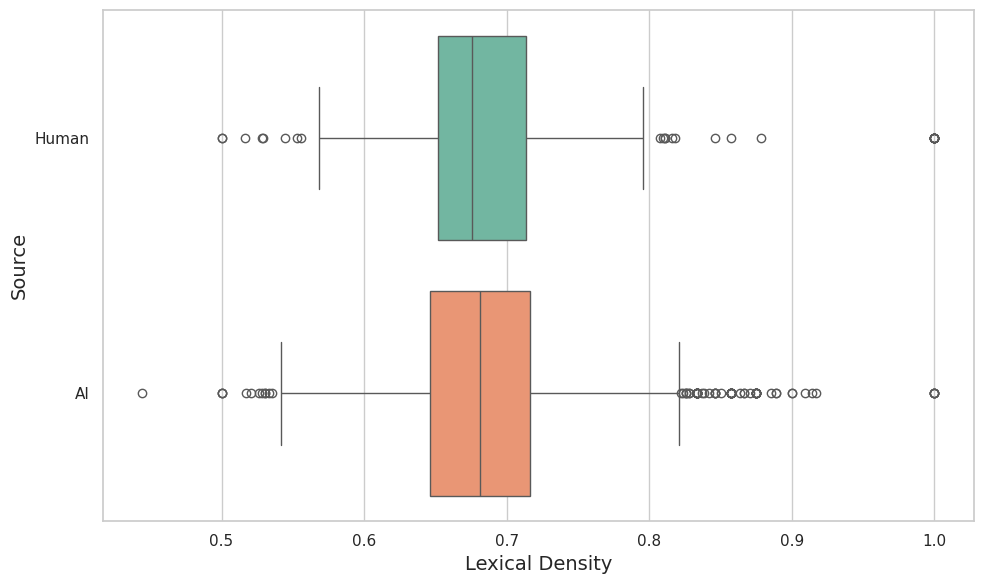

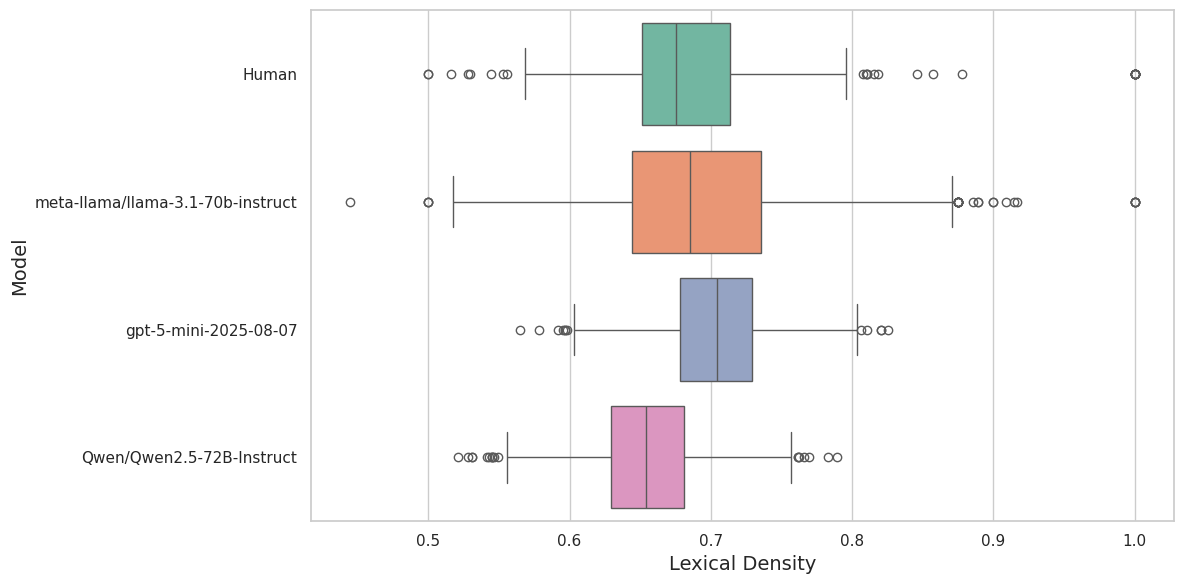

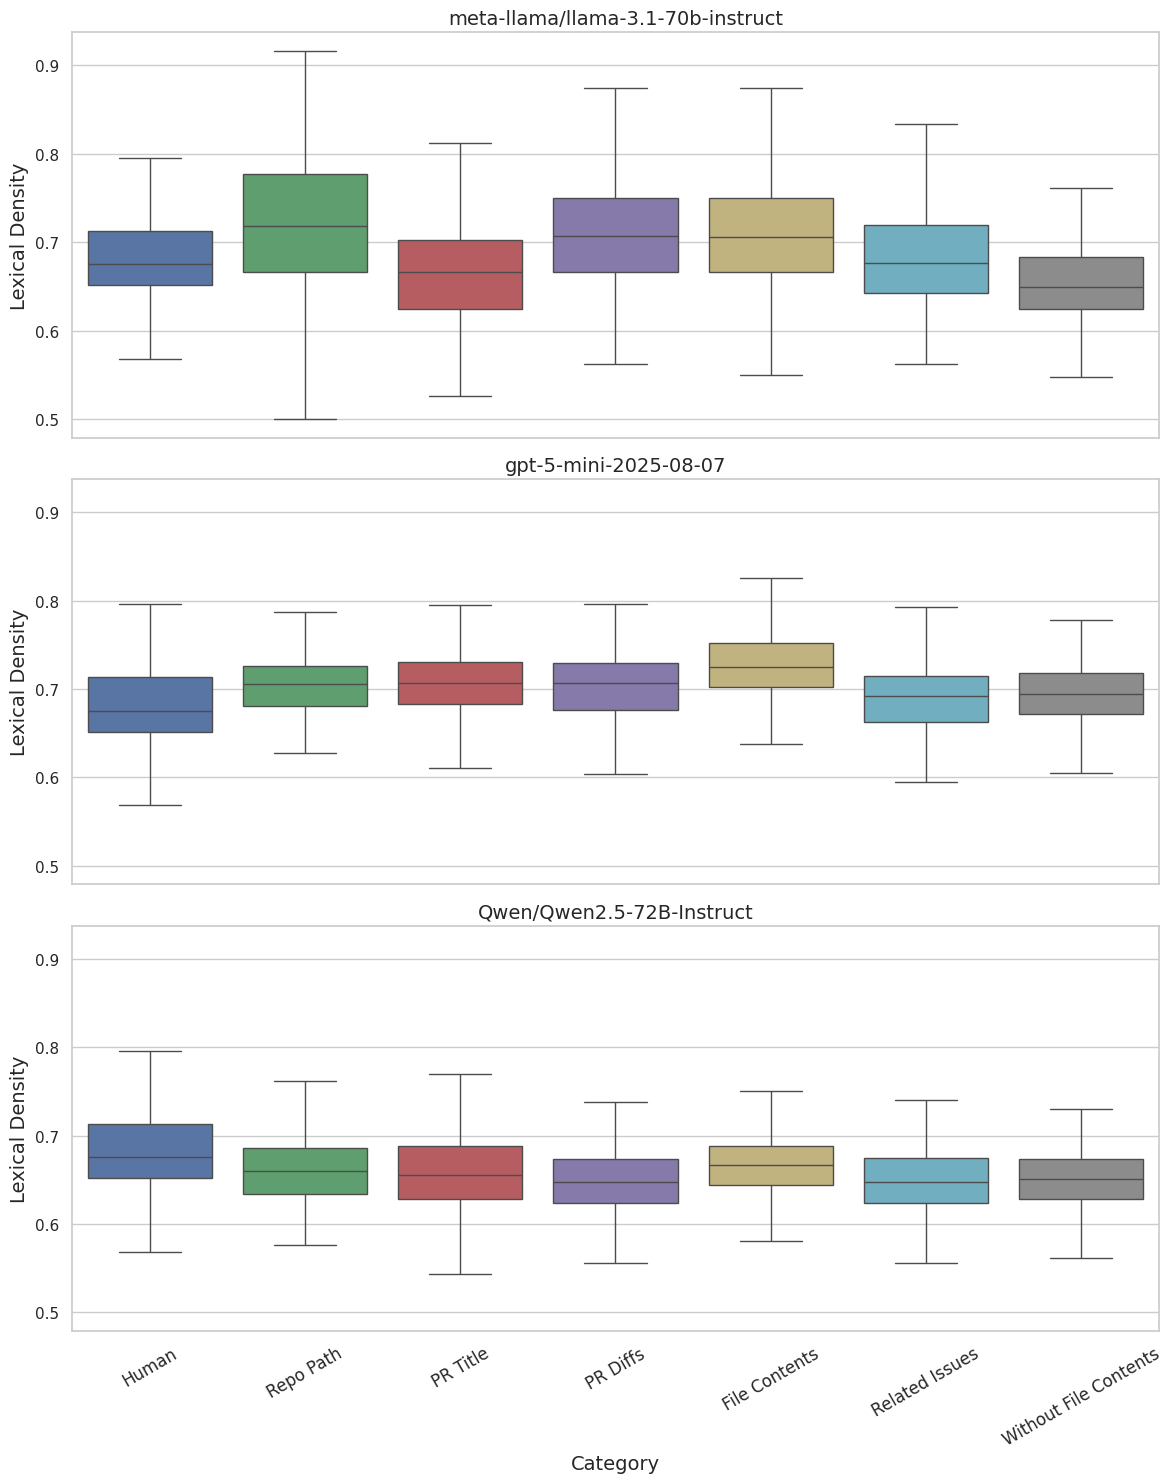

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='lexical_density', y='source', hue='source', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=14)
plt.ylabel('Source', fontsize=14)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
model_plot_df = combined_df.copy()
order = ['Human'] + TARGET_MODELS
sns.boxplot(data=model_plot_df, x='lexical_density', y='model', order=order, hue='model', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=14)
plt.ylabel('Model', fontsize=14)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

# Context comparison in the same style as other RQ3 notebooks:
# one panel per LLM (stacked vertically) with a Human baseline in each panel.
context_order = [CONTEXT_MAPPING[k] for k in ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']]
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    context_order[0]: '#55A868',
    context_order[1]: '#C44E52',
    context_order[2]: '#8172B2',
    context_order[3]: '#CCB974',
    context_order[4]: '#64B5CD',
    context_order[5]: '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    ai_slice = ai_df[ai_df['model'] == model][['lexical_density', 'Context_Name']].dropna().copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['lexical_density']].dropna().copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['lexical_density', 'Category']],
        ai_slice[['lexical_density', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='lexical_density',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('Lexical Density', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=12)

plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 6. Human vs AI Context Variations (Cliff's δ per Model)

In [8]:
rows = []
for model in TARGET_MODELS:
    model_slice = ai_df[ai_df['model'] == model]
    row = {'Model': model}
    for p_code, ctx_name in CONTEXT_MAPPING.items():
        ai_ctx = model_slice[model_slice['variation'] == p_code]
        ids = set(ai_ctx['normalized_pr_id'])
        human_ctx = human_df[human_df['normalized_pr_id'].isin(ids)]

        ai_vals = ai_ctx['lexical_density'].dropna().values
        human_vals = human_ctx['lexical_density'].dropna().values

        if len(ai_vals) == 0 or len(human_vals) == 0:
            row[ctx_name] = 'N/A'
            continue

        d = cliffs_delta(human_vals.tolist(), ai_vals.tolist())
        row[ctx_name] = f'{d:.3f} ({interpret_cd(d)})'

    rows.append(row)

effect_df = pd.DataFrame(rows).set_index('Model')
display(effect_df)

,Repo Path,PR Title,PR Diffs,File Contents,Related Issues,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,-0.325 (Small),0.148 (Small),-0.222 (Small),-0.262 (Small),0.015 (Negligible),0.316 (Small)
gpt-5-mini-2025-08-07,-0.293 (Small),-0.335 (Medium),-0.276 (Small),-0.510 (Large),-0.133 (Negligible),-0.180 (Small)
Qwen/Qwen2.5-72B-Instruct,0.255 (Small),0.294 (Small),0.408 (Medium),0.196 (Small),0.400 (Medium),0.401 (Medium)


## 7. Summary Table & Export

In [9]:
summary_rows = []
for model in ['Human'] + TARGET_MODELS:
    vals = combined_df[combined_df['model'] == model]['lexical_density'].dropna()
    summary_rows.append({
        'Model': model,
        'Metric': 'Lexical Density',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

out_dir = Path('outputs')
out_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(out_dir / 'rq3_lexical_density_summary.csv', index=False)
effect_df.reset_index().to_csv(out_dir / 'rq3_lexical_density_cliffs_delta_by_context.csv', index=False)
model_results_df.to_csv(out_dir / 'rq3_lexical_density_human_vs_model_stats.csv', index=False)
print('Saved outputs to outputs/.')
print('- rq3_lexical_density_summary.csv')
print('- rq3_lexical_density_cliffs_delta_by_context.csv')
print('- rq3_lexical_density_human_vs_model_stats.csv')

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Lexical Density,308,0.6895,0.6753,0.0783,0.5000,1.0000,0.6515,0.7132
1,meta-llama/llama-3.1-70b-instruct,Lexical Density,1844,0.6924,0.6852,0.0686,0.4444,1.0000,0.6439,0.7353
2,gpt-5-mini-2025-08-07,Lexical Density,1842,0.7034,0.7045,0.0382,0.5647,0.8255,0.6783,0.7290
3,Qwen/Qwen2.5-72B-Instruct,Lexical Density,1842,0.6547,0.6541,0.0386,0.5208,0.7895,0.6296,0.6809


Saved outputs to outputs/.
- rq3_lexical_density_summary.csv
- rq3_lexical_density_cliffs_delta_by_context.csv
- rq3_lexical_density_human_vs_model_stats.csv
